# 5. Evaluation: Pengujian pada Kelompok yang Tidak Digunakan Saat Pelatihan

Model terbaik diuji pada seluruh citra Kelompok 2. Split ini terpisah dari train dan validasi berdasarkan kelompok, bukan berdasarkan foto acak. Karena jumlah kelompok hanya tujuh dan test berasal dari satu kelompok, hasil tetap perlu dianggap sebagai estimasi awal.

In [1]:
import sys
from pathlib import Path
import json
import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve,
)


def find_project_dir():
    for base in (Path.cwd(), *Path.cwd().parents):
        for candidate in (base, base / Path("src/1-project/proyek_sain_data/src/10-project_citra")):
            if (candidate / "3-data_preparation").is_dir() and (candidate / "6-deployment").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Folder proyek 10-project_citra tidak ditemukan dari direktori kerja.")


PROJECT_DIR = find_project_dir()
DATA_PROCESSED = PROJECT_DIR / "3-data_preparation" / "data" / "processed"
MODEL_DIR = PROJECT_DIR / "4-modeling" / "models"
RESULTS_DIR = PROJECT_DIR / "5-evaluation" / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
test_df = pd.read_csv(DATA_PROCESSED / "test_features.csv")
manifest = pd.read_csv(DATA_PROCESSED / "dataset_manifest.csv")
if set(test_df["split"]) != {"test"}:
    raise ValueError("Test set mengandung baris dari split lain.")
test_groups = set(test_df["kelompok"])
train_val_groups = set(manifest.loc[manifest["split"].isin(["train", "val"]), "kelompok"])
if test_groups & train_val_groups:
    raise ValueError("Kelompok pada test set bocor ke data train/validasi.")
with (MODEL_DIR / "feature_columns.json").open(encoding="utf-8") as file:
    feature_cols = json.load(file)
model = joblib.load(MODEL_DIR / "best_model.joblib")
scaler = joblib.load(MODEL_DIR / "scaler.joblib")
X_test = scaler.transform(test_df[feature_cols].to_numpy())
y_test = test_df["label"].to_numpy()
preds = model.predict(X_test)
class_one_column = list(model.classes_).index(1)
probs = model.predict_proba(X_test)[:, class_one_column]
print(f"Data uji: {len(test_df)} citra dari kelompok {', '.join(sorted(test_groups))}")

Data uji: 30 citra dari kelompok kelompok 2


---
## 5.1 Evaluasi Metrik & Classification Report


In [2]:
accuracy = accuracy_score(y_test, preds)
macro_f1 = f1_score(y_test, preds, average="macro", zero_division=0)
metrics = {
    "model_name": type(model).__name__,
    "test_groups": sorted(test_groups),
    "test_samples": int(len(test_df)),
    "test_accuracy": float(accuracy),
    "test_precision_weighted": float(precision_score(y_test, preds, average="weighted", zero_division=0)),
    "test_recall_weighted": float(recall_score(y_test, preds, average="weighted", zero_division=0)),
    "test_f1_weighted": float(f1_score(y_test, preds, average="weighted", zero_division=0)),
    "test_f1_macro": float(macro_f1),
    "test_roc_auc": float(roc_auc_score(y_test, probs)),
    "confusion_matrix": confusion_matrix(y_test, preds, labels=[0, 1]).tolist(),
    "classification_report": classification_report(
        y_test, preds, labels=[0, 1], target_names=["Berantakan", "Rapi"],
        output_dict=True, zero_division=0,
    ),
    "target_accuracy_met": bool(accuracy >= 0.85),
    "target_macro_f1_met": bool(macro_f1 >= 0.83),
}
roc_auc = metrics["test_roc_auc"]
with (RESULTS_DIR / "evaluation_metrics.json").open("w", encoding="utf-8") as file:
    json.dump(metrics, file, indent=2)
pd.DataFrame({
    "rel_path": test_df["rel_path"],
    "kelompok": test_df["kelompok"],
    "actual_label": y_test,
    "predicted_label": preds,
    "probability_rapi": probs,
}).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
print(json.dumps(metrics, indent=2))
print("Metrik dan prediksi tersimpan di", RESULTS_DIR)

{
  "model_name": "GradientBoostingClassifier",
  "test_groups": [
    "kelompok 2"
  ],
  "test_samples": 30,
  "test_accuracy": 0.6,
  "test_precision_weighted": 0.7777777777777779,
  "test_recall_weighted": 0.6,
  "test_f1_weighted": 0.5238095238095238,
  "test_f1_macro": 0.5238095238095238,
  "test_roc_auc": 0.72,
  "confusion_matrix": [
    [
      15,
      0
    ],
    [
      12,
      3
    ]
  ],
  "classification_report": {
    "Berantakan": {
      "precision": 0.5555555555555556,
      "recall": 1.0,
      "f1-score": 0.7142857142857143,
      "support": 15.0
    },
    "Rapi": {
      "precision": 1.0,
      "recall": 0.2,
      "f1-score": 0.3333333333333333,
      "support": 15.0
    },
    "accuracy": 0.6,
    "macro avg": {
      "precision": 0.7777777777777778,
      "recall": 0.6,
      "f1-score": 0.5238095238095238,
      "support": 30.0
    },
    "weighted avg": {
      "precision": 0.7777777777777779,
      "recall": 0.6,
      "f1-score": 0.5238095238095238,
 

---
## 5.2 Visualisasi Confusion Matrix & Kurva ROC


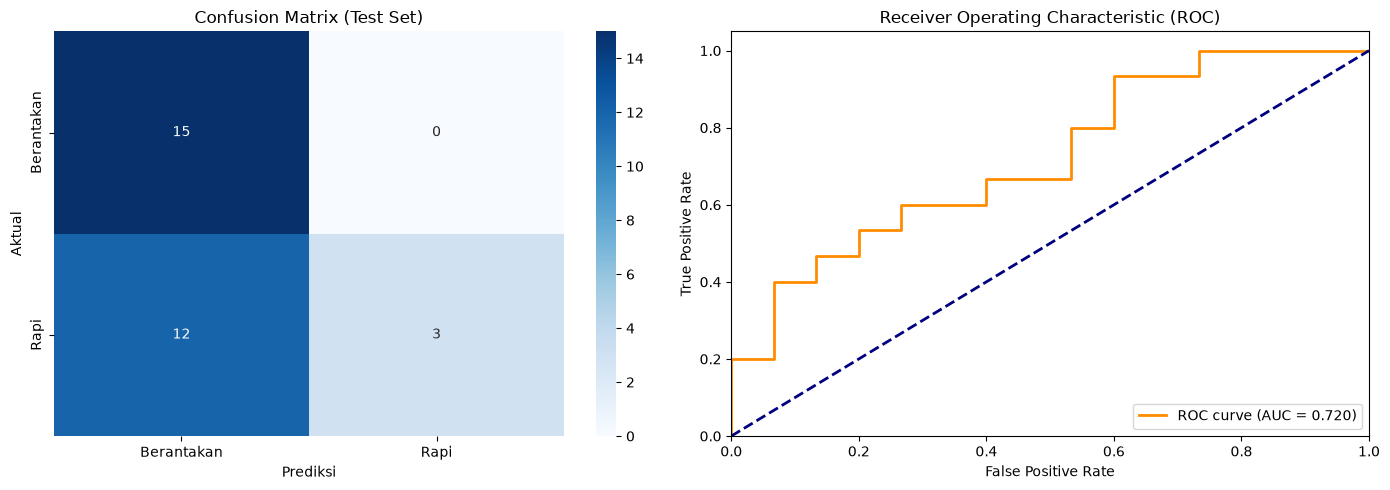

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Berantakan', 'Rapi'], yticklabels=['Berantakan', 'Rapi'], ax=ax1)
ax1.set_title("Confusion Matrix (Test Set)")
ax1.set_xlabel("Prediksi")
ax1.set_ylabel("Aktual")

# 2. Kurva ROC
fpr, tpr, _ = roc_curve(y_test, probs)
ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('Receiver Operating Characteristic (ROC)')
ax2.legend(loc="lower right")

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'evaluation_plots.png', dpi=300)
plt.show()


---
## 5.3 Analisis Kepentingan Fitur (*Feature Importance*)


C:\Users\SUB-LENOVO\AppData\Local\Temp\ipykernel_7028\1559315907.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_imp.head(10), x='Importance', y='Fitur', palette='viridis')


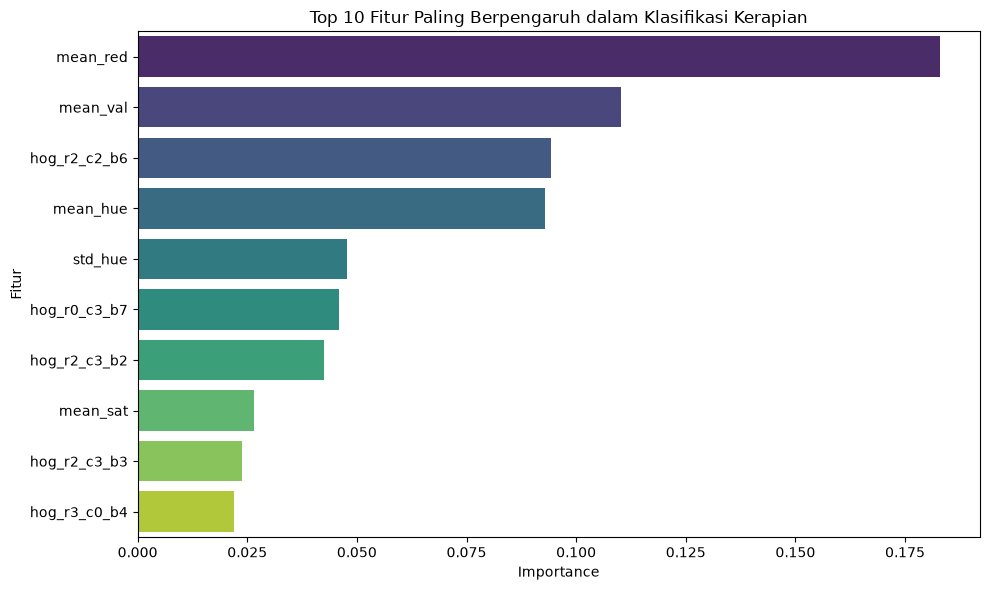

,Fitur,Importance
0,mean_red,0.182945
12,mean_val,0.110287
122,hog_r2_c2_b6,0.094202
8,mean_hue,0.092969
9,std_hue,0.047681
60,hog_r0_c3_b7,0.045977
127,hog_r2_c3_b2,0.042460
10,mean_sat,0.026526
128,hog_r2_c3_b3,0.023804
138,hog_r3_c0_b4,0.021925


In [4]:
if hasattr(model, 'feature_importances_'):
    importances = model.feature_importances_
    df_imp = pd.DataFrame({'Fitur': feature_cols, 'Importance': importances}).sort_values('Importance', ascending=False)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(data=df_imp.head(10), x='Importance', y='Fitur', palette='viridis')
    plt.title("Top 10 Fitur Paling Berpengaruh dalam Klasifikasi Kerapian")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'feature_importance.png', dpi=300)
    plt.show()
    
    display(df_imp.head(10))
